# EOF and complex (Hilbert) EOF of the mean seasonal cycle — complete data

Input: `mean_seasonal_cycle.nc` — 12 monthly maps (Jan–Dec). The methods follow `../no-coslat-eof.ipynb`
(`use_coslat=False`), with two differences that come from the input being a 12-step
climatology rather than a 276-month record:

* At most 12 modes exist, and EOF removes each pixel's 12-month mean first, so the modes
  describe the seasonal deviations from the annual-mean map.
* The seasonal cycle is periodic (December wraps into January), which is exactly what the
  FFT-based Hilbert transform assumes. So the complex EOF uses `padding="none"`; the
  exponential end-padding used for the long record would add artificial edges here.

Reference boxes: mode *k* is referenced to box *k* (same boxes as `../no-coslat-eof.ipynb`).

In [1]:
# Setup: config + imports
import os
import itertools
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from xeofs.single import EOF, HilbertEOF

OUT_DIR = "../../Figures/climatology/seasonal-cycle-eofs"
os.makedirs(OUT_DIR, exist_ok=True)

cycle = xr.open_dataarray("mean_seasonal_cycle.nc").load()
mnames = list(cycle["month_name"].values)
mpos   = np.arange(1, 13)
N_MODES = cycle.sizes["month"]          # 12 samples -> at most 12 modes
cycle

<xarray.DataArray 'co_mmr_midtrop' (month: 12, lat: 36, lon: 61)> Size: 211kB
array([[[8.54975811e-08, 8.51977179e-08, 8.50447847e-08, ...,
         8.35957588e-08, 8.36861896e-08, 8.37892041e-08],
        [8.60178081e-08, 8.59399625e-08, 8.54771780e-08, ...,
         8.34251955e-08, 8.34157842e-08, 8.35325912e-08],
        [8.67035047e-08, 8.65309487e-08, 8.59941862e-08, ...,
         8.34343192e-08, 8.33395303e-08, 8.34259465e-08],
        ...,
        [9.84392851e-08, 9.86240129e-08, 9.78514525e-08, ...,
         8.69264937e-08, 8.69478739e-08, 8.77479741e-08],
        [9.86252536e-08, 9.83360893e-08, 9.65515019e-08, ...,
         8.85850107e-08, 8.73833140e-08, 8.73570464e-08],
        [9.77288369e-08, 9.57559470e-08, 9.59781044e-08, ...,
         8.70764608e-08, 8.86072649e-08, 9.06617606e-08]],

       [[8.40604751e-08, 8.37875429e-08, 8.37761007e-08, ...,
         8.42500519e-08, 8.42670685e-08, 8.43002511e-08],
        [8.46322355e-08, 8.45275726e-08, 8.40666787e-08, ...,
         8.38053908e-08, 8.38170613e-08, 8.38338953e-08],
        [8.51522904e-08, 8.49222361e-08, 8.46719023e-08, ...,
         8.34648138e-08, 8.34423801e-08, 8.35084757e-08],
...
         8.54988910e-08, 8.50612384e-08, 8.53213730e-08],
        [9.24778238e-08, 9.24934783e-08, 9.07891696e-08, ...,
         8.71174088e-08, 8.60358806e-08, 8.55183181e-08],
        [9.18775484e-08, 9.04060588e-08, 9.05492792e-08, ...,
         8.67713732e-08, 8.72075102e-08, 8.79944298e-08]],

       [[8.20530683e-08, 8.18776912e-08, 8.17810231e-08, ...,
         8.17524528e-08, 8.18669765e-08, 8.20357554e-08],
        [8.25208501e-08, 8.24127734e-08, 8.22018133e-08, ...,
         8.14806692e-08, 8.15594987e-08, 8.16860285e-08],
        [8.30484027e-08, 8.28488678e-08, 8.27923305e-08, ...,
         8.14074280e-08, 8.14305204e-08, 8.15733188e-08],
        ...,
        [9.45401710e-08, 9.46052573e-08, 9.33044272e-08, ...,
         8.52580130e-08, 8.50148470e-08, 8.55020174e-08],
        [9.46829098e-08, 9.45139236e-08, 9.24742393e-08, ...,
         8.68368621e-08, 8.57042666e-08, 8.53942175e-08],
        [9.33725414e-08, 9.15826027e-08, 9.14369053e-08, ...,
         8.60310983e-08, 8.71978360e-08, 8.85827886e-08]]],
      shape=(12, 36, 61))
Coordinates:
  * month       (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat         (lat) float32 144B 14.5 15.5 16.5 17.5 ... 46.5 47.5 48.5 49.5
  * lon         (lon) float32 244B -126.5 -125.5 -124.5 ... -68.5 -67.5 -66.5
    month_name  (month) <U3 144B 'Jan' 'Feb' 'Mar' 'Apr' ... 'Oct' 'Nov' 'Dec'
Attributes:
    long_name:  Mean seasonal cycle of AIRS CO mid-troposphere MMR (complete ...
    units:      kg kg-1
    source:     complete_data.nc
    period:     2003-01 to 2025-12
    method:     per-pixel average of all years for each calendar month

In [2]:
# Helpers: reference boxes, map drawing, colormap choice
lons = cycle["lon"].values
lats = cycle["lat"].values
ext = [float(lons.min()), float(lons.max()), float(lats.min()), float(lats.max())]

BOXES = {
    1: dict(LAT0=31, LAT1=36, LON0=-117, LON1=-112),
    2: dict(LAT0=45, LAT1=49, LON0=-85,  LON1=-70),
    3: dict(LAT0=17, LAT1=19, LON0=-102, LON1=-99),
}
MODES_CMP = [1, 2, 3]

def box_mean(da, k):
    b = BOXES[k]
    return da.sel(lat=slice(b["LAT0"], b["LAT1"]), lon=slice(b["LON0"], b["LON1"])).mean(("lat", "lon"))

def box_label(k):
    b = BOXES[k]
    return f"box {k} [{b['LAT0']}-{b['LAT1']}°N, {b['LON0']}-{b['LON1']}°E]"

def draw_box(ax, k, color="#ccff00"):
    b = BOXES[k]
    ax.plot([b["LON0"], b["LON1"], b["LON1"], b["LON0"], b["LON0"]],
            [b["LAT0"], b["LAT0"], b["LAT1"], b["LAT1"], b["LAT0"]],
            "-", color=color, lw=1.8, transform=ccrs.PlateCarree())

def choose_cmap_and_range(data, robust=True, plow=2, phigh=98):
    """Diverging RdBu_r if the data have both signs, otherwise a sequential map."""
    vals = np.asarray(data)
    vals = vals[np.isfinite(vals)]
    lo, hi = np.nanpercentile(vals, [plow, phigh]) if robust else (np.nanmin(vals), np.nanmax(vals))
    if hi > 0 and lo < 0:
        vext = max(abs(lo), abs(hi))
        return "RdBu_r", -vext, vext
    elif hi > 0:
        return "Reds", 0.0, hi
    return "Blues_r", lo, 0.0

def map_panel(ax, data, cmap, label, title, vmin=None, vmax=None, norm=None):
    ax.set_extent(ext, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6, edgecolor="k")
    ax.add_feature(cfeature.BORDERS,   linewidth=0.4, edgecolor="#555")
    ax.add_feature(cfeature.STATES,    linewidth=0.25, edgecolor="#888")
    pcm = ax.pcolormesh(lons, lats, data, transform=ccrs.PlateCarree(),
                        cmap=cmap, vmin=vmin, vmax=vmax, norm=norm, shading="nearest")
    gl = ax.gridlines(draw_labels=True, linewidth=0, color="none")
    gl.top_labels = gl.right_labels = False
    cb = ax.figure.colorbar(pcm, ax=ax, orientation="vertical", fraction=0.03, pad=0.06)
    cb.set_label(label, fontsize=9)
    ax.set_title(title, fontsize=11, pad=6)
    return cb

def month_axis(ax):
    ax.set_xticks(mpos); ax.set_xticklabels(mnames)
    ax.axhline(0, color="k", lw=0.5)
    ax.grid(alpha=0.4)

## EOF

Mode  1:  89.8% of variance
Mode  2:   6.5% of variance
Mode  3:   2.7% of variance
Mode  4:   0.4% of variance
Mode  5:   0.2% of variance
Mode  6:   0.2% of variance
Mode  7:   0.1% of variance
Mode  8:   0.0% of variance
Mode  9:   0.0% of variance
Mode 10:   0.0% of variance
Mode 11:   0.0% of variance
Mode 12:   0.0% of variance


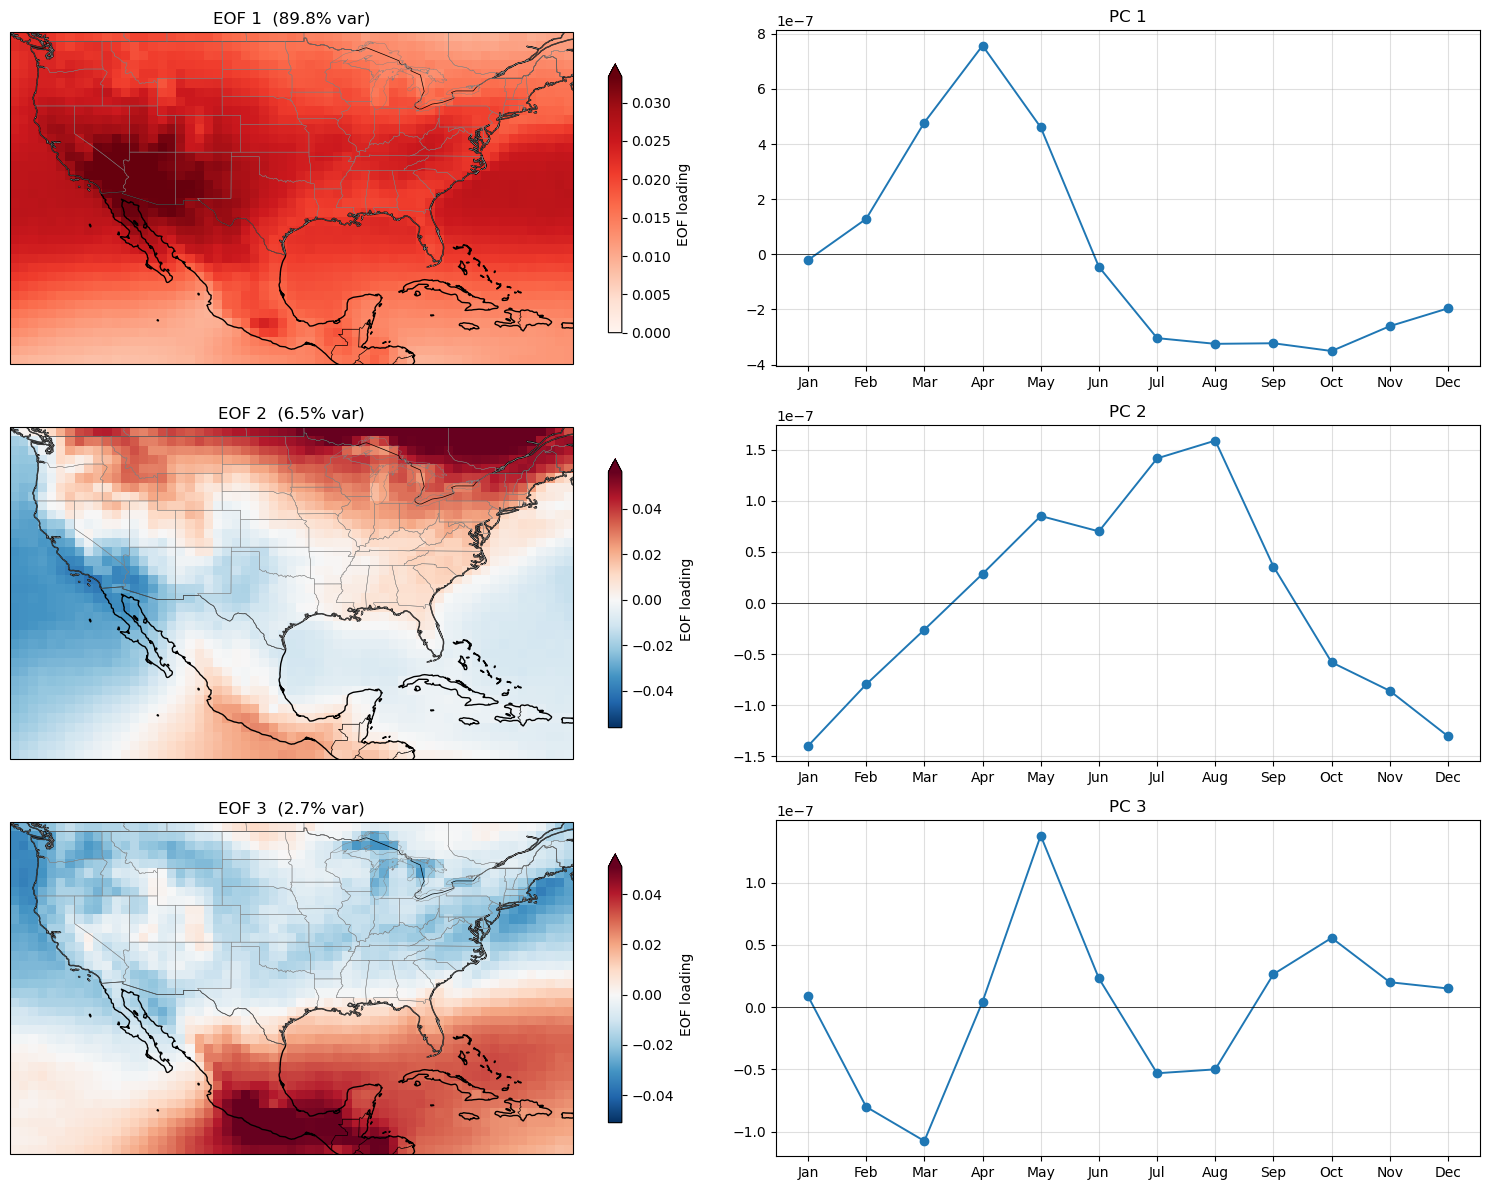

Saved -> ../../Figures/climatology/seasonal-cycle-eofs\eof_seasonal_cycle.png


In [3]:
model = EOF(n_modes=N_MODES, use_coslat=False)
model.fit(cycle, dim="month")
eofs   = model.components()                       # (mode, lat, lon)
pcs    = model.scores()                           # (mode, month)
expvar = model.explained_variance_ratio().values * 100
for i, v in enumerate(expvar, start=1):
    print(f"Mode {i:2d}: {v:5.1f}% of variance")

# Plot first 3 modes: spatial pattern + PC.
n_show = 3
fig_eof = plt.figure(figsize=(15, 4 * n_show))
for i in range(n_show):
    eof_i = eofs.sel(mode=i+1)
    cmap_i, vmin_i, vmax_i = choose_cmap_and_range(eof_i.values)

    ax_map = fig_eof.add_subplot(n_show, 2, 2*i + 1, projection=ccrs.PlateCarree())
    eof_i.plot(
        ax=ax_map, transform=ccrs.PlateCarree(), cmap=cmap_i,
        vmin=vmin_i, vmax=vmax_i,
        cbar_kwargs={"label": "EOF loading", "shrink": 0.8},
    )
    ax_map.coastlines()
    ax_map.add_feature(cfeature.BORDERS, lw=0.5)
    ax_map.add_feature(cfeature.STATES, lw=0.3, edgecolor="gray")
    ax_map.set_title(f"EOF {i+1}  ({expvar[i]:.1f}% var)")

    ax_pc = fig_eof.add_subplot(n_show, 2, 2*i + 2)
    ax_pc.plot(mpos, pcs.sel(mode=i+1).values, "o-", lw=1.4)
    month_axis(ax_pc)
    ax_pc.set_title(f"PC {i+1}")

plt.tight_layout()
out_eof = os.path.join(OUT_DIR, "eof_seasonal_cycle.png")
fig_eof.savefig(out_eof, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_eof)

### EOF regression maps and box reconstructions

Left: regression of the seasonal cycle on the mode-*k* index (the mode-*k* reconstruction
averaged over box *k*), ×100, so 100% means the same seasonal swing as the box average.
Right: the mode-*k* reconstruction (EOF × PC) averaged over box *k*.

EOF 1: regression min = 22.5, max = 106.1
EOF 2: regression min = -80.9, max = 124.3
EOF 3: regression min = -48.1, max = 111.2


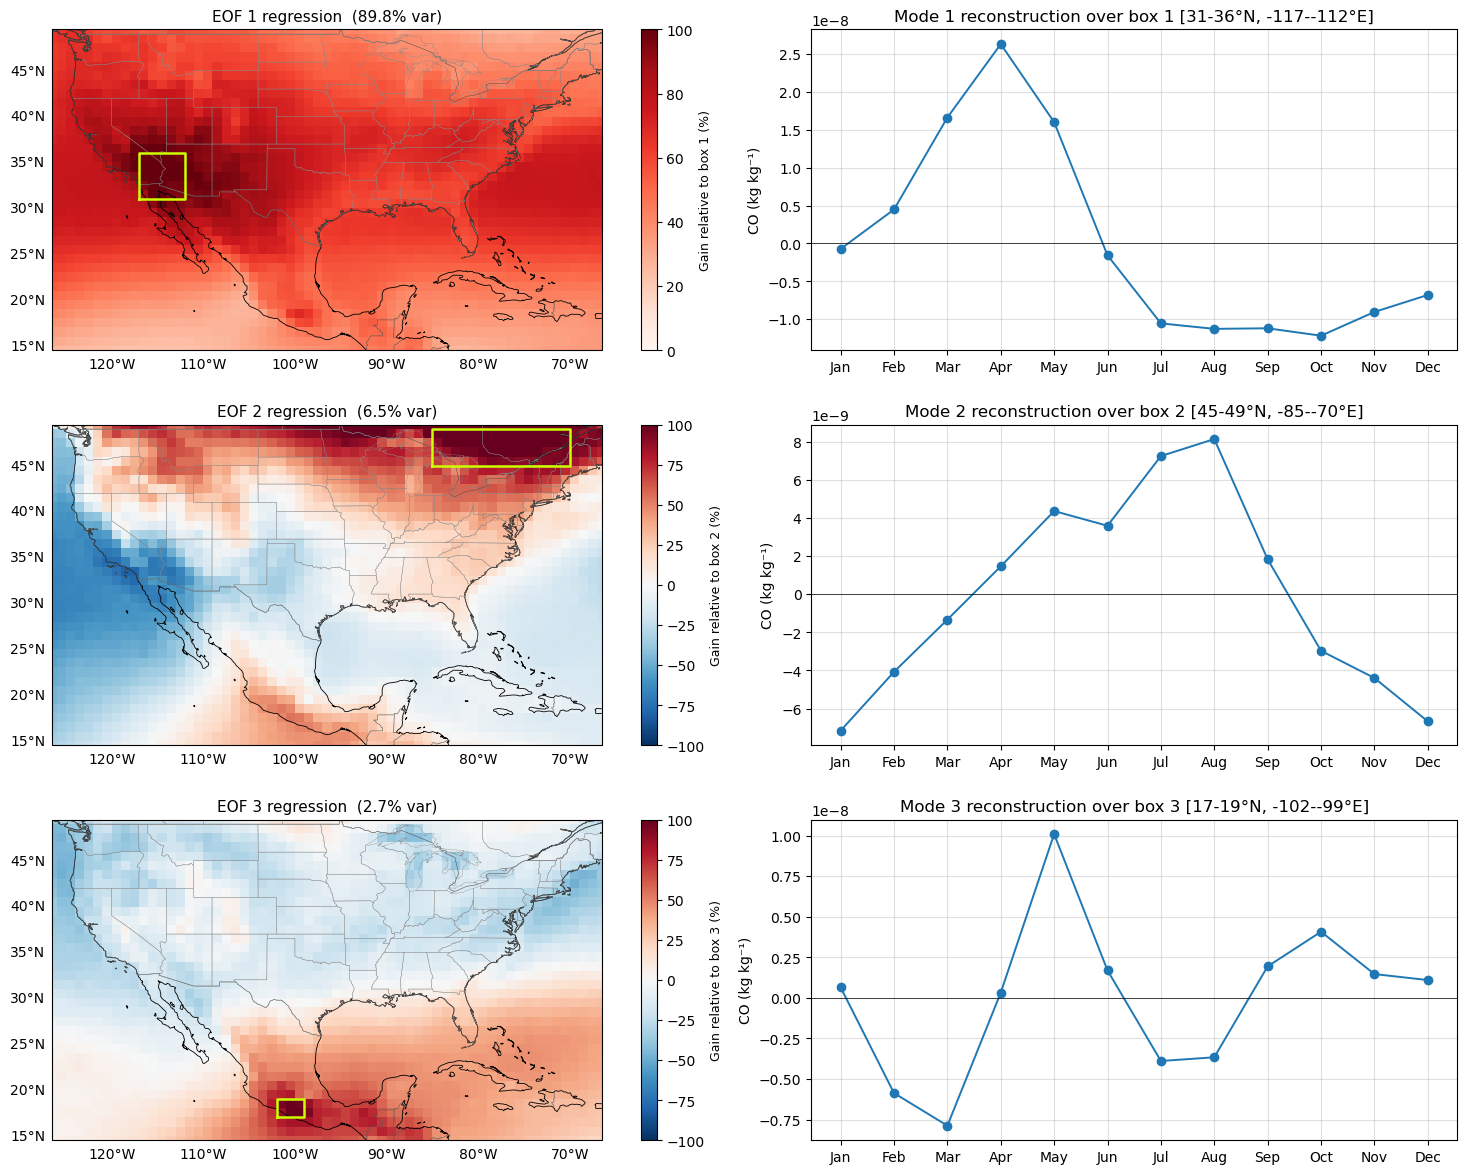

Saved -> ../../Figures/climatology/seasonal-cycle-eofs\eof_regr_recon_box_modes123.png


In [4]:
fig_rr, axes_rr = plt.subplots(n_show, 2, figsize=(15, 4 * n_show),
                               gridspec_kw={"width_ratios": [1, 1]})
for i, k in enumerate(MODES_CMP):
    recon_k = box_mean(eofs.sel(mode=k) * pcs.sel(mode=k), k)            # (month,)
    regr_k  = (100 * xr.cov(cycle, recon_k, dim="month") / xr.cov(recon_k, recon_k, dim="month")).values

    # left: regression map (replace the plain axis with a map axis)
    axes_rr[i, 0].remove()
    ax_map = fig_rr.add_subplot(n_show, 2, 2*i + 1, projection=ccrs.PlateCarree())
    cmap_k, vmin_k, _ = choose_cmap_and_range(regr_k)
    vmin_k = -100 if vmin_k < 0 else 0                                    # clip at 100% (box average)
    map_panel(ax_map, regr_k, cmap_k, f"Gain relative to box {k} (%)",
              f"EOF {k} regression  ({expvar[k-1]:.1f}% var)", vmin=vmin_k, vmax=100)
    draw_box(ax_map, k)

    # right: reconstruction over the box
    ax_rc = axes_rr[i, 1]
    ax_rc.plot(mpos, recon_k.values, "o-", lw=1.4, color="#1f77b4")
    month_axis(ax_rc)
    ax_rc.set_ylabel("CO (kg kg⁻¹)")
    ax_rc.set_title(f"Mode {k} reconstruction over {box_label(k)}")
    print(f"EOF {k}: regression min = {np.nanmin(regr_k):.1f}, max = {np.nanmax(regr_k):.1f}")

plt.tight_layout()
out_rr = os.path.join(OUT_DIR, "eof_regr_recon_box_modes123.png")
fig_rr.savefig(out_rr, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_rr)

## Do the variances add to 100%?

In [5]:
total = expvar.sum()
print(f"Modes returned : {len(expvar)}")
print(f"Sum of percentage variances : {total:.6f} %")
print(f"Equal to 100%? {np.isclose(total, 100.0)}")

Modes returned : 12
Sum of percentage variances : 100.000000 %
Equal to 100%? True


## Complex (Hilbert) EOF

Ordinary EOF gives *standing* patterns. Complex EOF adds the Hilbert transform of each pixel's
seasonal cycle as an imaginary part (the same signal a quarter cycle later), so each mode has
an **amplitude** (where it acts) and a **phase** (when in the year it peaks).

In [6]:
cmodel = HilbertEOF(n_modes=N_MODES, use_coslat=False, padding="none", solver="full")
cmodel.fit(cycle, dim="month")
cexpvar = cmodel.explained_variance_ratio().values * 100

print("Complex (Hilbert) EOF — variance explained")
for i, v in enumerate(cexpvar, start=1):
    print(f"  Mode {i:2d}: {v:5.1f}%")
print(f"\n  First 3 modes together: {cexpvar[:3].sum():.1f}%")
print(f"  Sum of all modes      : {cexpvar.sum():.6f}%  (equal to 100%? {np.isclose(cexpvar.sum(), 100.0)})")

Complex (Hilbert) EOF — variance explained
  Mode  1:  94.8%
  Mode  2:   4.4%
  Mode  3:   0.6%
  Mode  4:   0.2%
  Mode  5:   0.1%
  Mode  6:   0.0%
  Mode  7:   0.0%
  Mode  8:   0.0%
  Mode  9:   0.0%
  Mode 10:   0.0%
  Mode 11:   0.0%
  Mode 12:   0.0%

  First 3 modes together: 99.7%
  Sum of all modes      : 100.000000%  (equal to 100%? True)


In [7]:
# Complex components and scores, and their amplitude / phase parts.
ceofs = cmodel.components()              # (mode, lat, lon)  complex
cpcs  = cmodel.scores()                  # (mode, month)     complex

ceof_amp = cmodel.components_amplitude()     # spatial amplitude
ceof_pha = cmodel.components_phase()         # spatial phase (radians, -pi..pi)
cpc_amp  = cmodel.scores_amplitude()         # temporal amplitude
cpc_pha  = cmodel.scores_phase()             # temporal phase (radians)

print("components :", ceofs.dims, ceofs.dtype)
print("scores     :", cpcs.dims, cpcs.dtype)

# --- per-mode period from the slope of the unwrapped PC phase ---
time_axis = np.arange(cpcs.sizes["month"])   # 1 step = 1 month
print(f"\n{'Mode':>4} {'Var%':>7} {'CumVar%':>8} {'Period(mo)':>11}")
mode_periods = {}
cum = 0.0
for k in range(1, 6):
    cum += cexpvar[k-1]
    ph_unwrap = np.unwrap(cpc_pha.sel(mode=k).values)
    slope = np.polyfit(time_axis, ph_unwrap, 1)[0]         # rad / month
    mode_periods[k] = np.nan if slope == 0 else 2*np.pi / slope
    print(f"{k:>4} {cexpvar[k-1]:>7.2f} {cum:>8.2f} {mode_periods[k]:>11.2f}")

components : ('mode', 'lat', 'lon') complex128
scores     : ('mode', 'month') complex128

Mode    Var%  CumVar%  Period(mo)
   1   94.76    94.76       11.38
   2    4.38    99.14        5.47
   3    0.61    99.75        3.69
   4    0.19    99.94        2.75
   5    0.06    99.99        3.25


**Spatial amplitude and phase of the first three complex modes.**

Mode 2: phase wraps the 0/360 seam -> showing full colorbar
Mode 3: phase wraps the 0/360 seam -> showing full colorbar


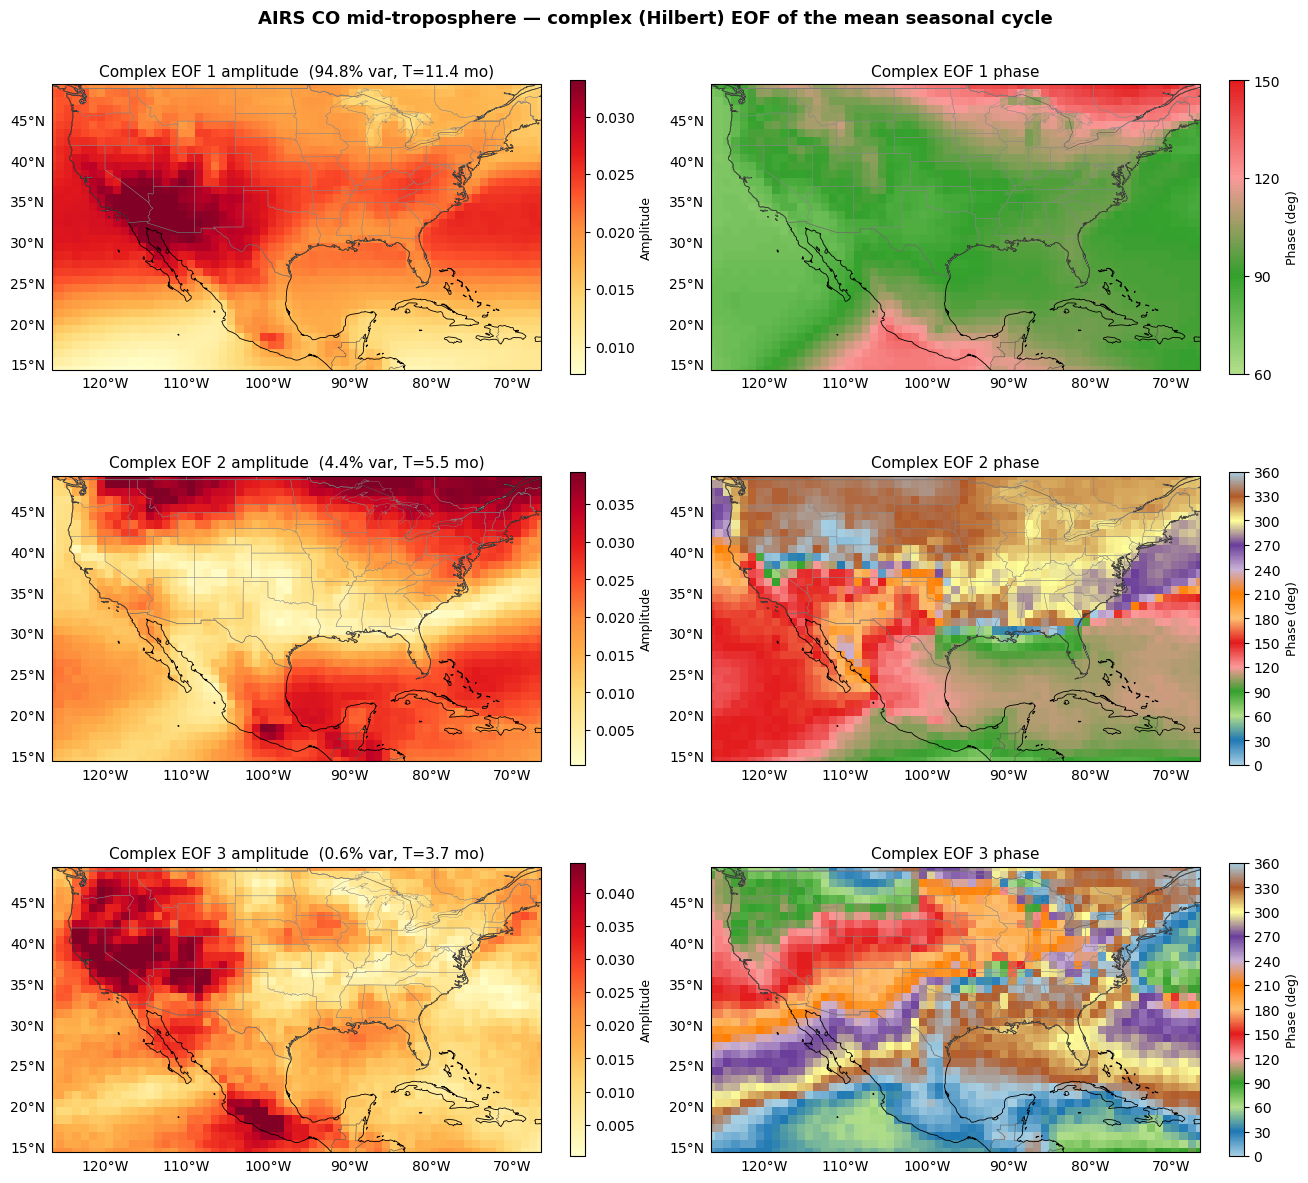

Saved -> ../../Figures/climatology/seasonal-cycle-eofs\ceof_amp_phase_seasonal_cycle.png


In [8]:
distinct_colors = plt.get_cmap("Paired").colors   # 12 distinct colors, one per 30-deg bin

def build_fixed_phase_cmap():
    bin_colors = list(itertools.islice(itertools.cycle(distinct_colors), 12))
    cmap = mcolors.LinearSegmentedColormap.from_list("phase_fixed", bin_colors + [bin_colors[0]], N=360)
    return cmap, mcolors.Normalize(vmin=0, vmax=360)

phase_cmap, phase_norm = build_fixed_phase_cmap()

def circular_range(deg_vals):
    v = np.sort(np.mod(deg_vals[np.isfinite(deg_vals)], 360))
    if v.size == 0:
        return 0.0, 360.0, False
    gaps = np.diff(np.concatenate([v, [v[0] + 360]]))
    k = np.argmax(gaps)
    start = v[(k + 1) % v.size]
    end = start + (360 - gaps[k])
    return float(start), float(end), end > 360

def crop_to_30deg(lo, hi):
    return float(np.floor(lo / 30) * 30), float(np.ceil(hi / 30) * 30)

fig_ca, axes_ca = plt.subplots(n_show, 2, figsize=(13, 4 * n_show),
                               subplot_kw={"projection": ccrs.PlateCarree()}, constrained_layout=True)
for i in range(n_show):
    mode_k = i + 1
    amp_i = ceof_amp.sel(mode=mode_k).values
    pha_i = np.rad2deg(ceof_pha.sel(mode=mode_k).values) % 360

    map_panel(axes_ca[i, 0], amp_i, "YlOrRd", "Amplitude",
              f"Complex EOF {mode_k} amplitude  ({cexpvar[i]:.1f}% var, T={mode_periods[mode_k]:.1f} mo)",
              vmax=np.nanpercentile(amp_i, 98))

    start, end, wraps = circular_range(pha_i)
    cb = map_panel(axes_ca[i, 1], pha_i, phase_cmap, "Phase (deg)",
                   f"Complex EOF {mode_k} phase", norm=phase_norm)
    if not wraps:
        lo30, hi30 = crop_to_30deg(start, end)
        cb.ax.set_ylim(lo30, hi30)
        ticks = np.arange(lo30, hi30 + 1e-6, 30)
    else:
        ticks = np.arange(0, 361, 30)
        print(f"Mode {mode_k}: phase wraps the 0/360 seam -> showing full colorbar")
    cb.set_ticks(ticks)

fig_ca.suptitle("AIRS CO mid-troposphere — complex (Hilbert) EOF of the mean seasonal cycle",
                fontsize=13, fontweight="bold")
out_ca = os.path.join(OUT_DIR, "ceof_amp_phase_seasonal_cycle.png")
fig_ca.savefig(out_ca, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_ca)

**The complex PCs:** real and imaginary parts with the amplitude envelope.

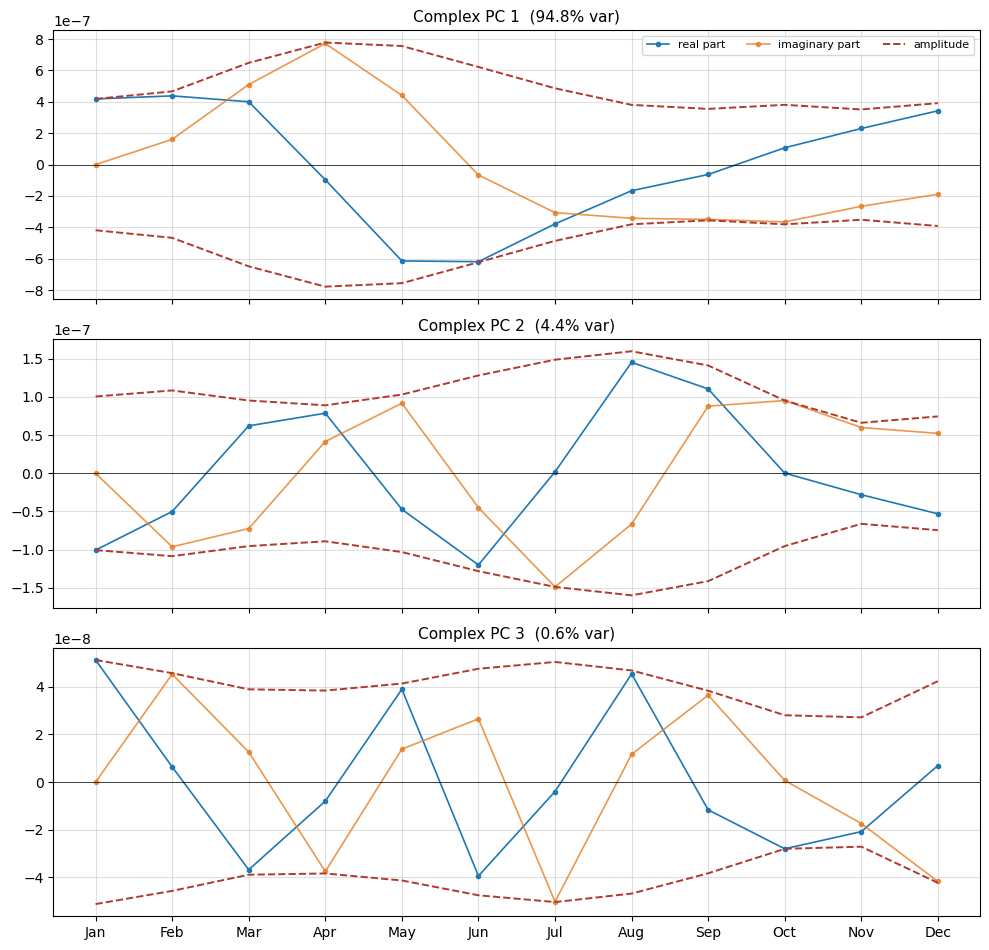

Saved -> ../../Figures/climatology/seasonal-cycle-eofs\ceof_pcs_seasonal_cycle.png


In [9]:
fig_cp, axes_cp = plt.subplots(n_show, 1, figsize=(10, 3.2 * n_show), sharex=True)
for i in range(n_show):
    ax = axes_cp[i]
    pc_i = cpcs.sel(mode=i+1).values
    env = np.abs(pc_i)
    ax.plot(mpos, pc_i.real, "o-", lw=1.2, ms=3, color="#1f77b4", label="real part")
    ax.plot(mpos, pc_i.imag, "o-", lw=1.2, ms=3, color="#e67e22", alpha=0.8, label="imaginary part")
    ax.plot(mpos, env,  lw=1.4, color="#b03a2e", ls="--", label="amplitude")
    ax.plot(mpos, -env, lw=1.4, color="#b03a2e", ls="--")
    month_axis(ax)
    ax.set_title(f"Complex PC {i+1}  ({cexpvar[i]:.1f}% var)", fontsize=11)
    if i == 0:
        ax.legend(fontsize=8, loc="upper right", ncol=3)
fig_cp.tight_layout()
out_cp = os.path.join(OUT_DIR, "ceof_pcs_seasonal_cycle.png")
fig_cp.savefig(out_cp, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_cp)

### Complex EOF relative amplitude and relative phase (mode *k* vs box *k*)

Left: |c(x)| / |box reference| × 100 (clipped at 100% = box). Right: phase of
c(x)·conj(box reference); 0 = in phase with the box, positive = peaks later than the box.

Mode 1: box coherence = 0.9992
Mode 2: box coherence = 0.9990
Mode 3: box coherence = 0.9911


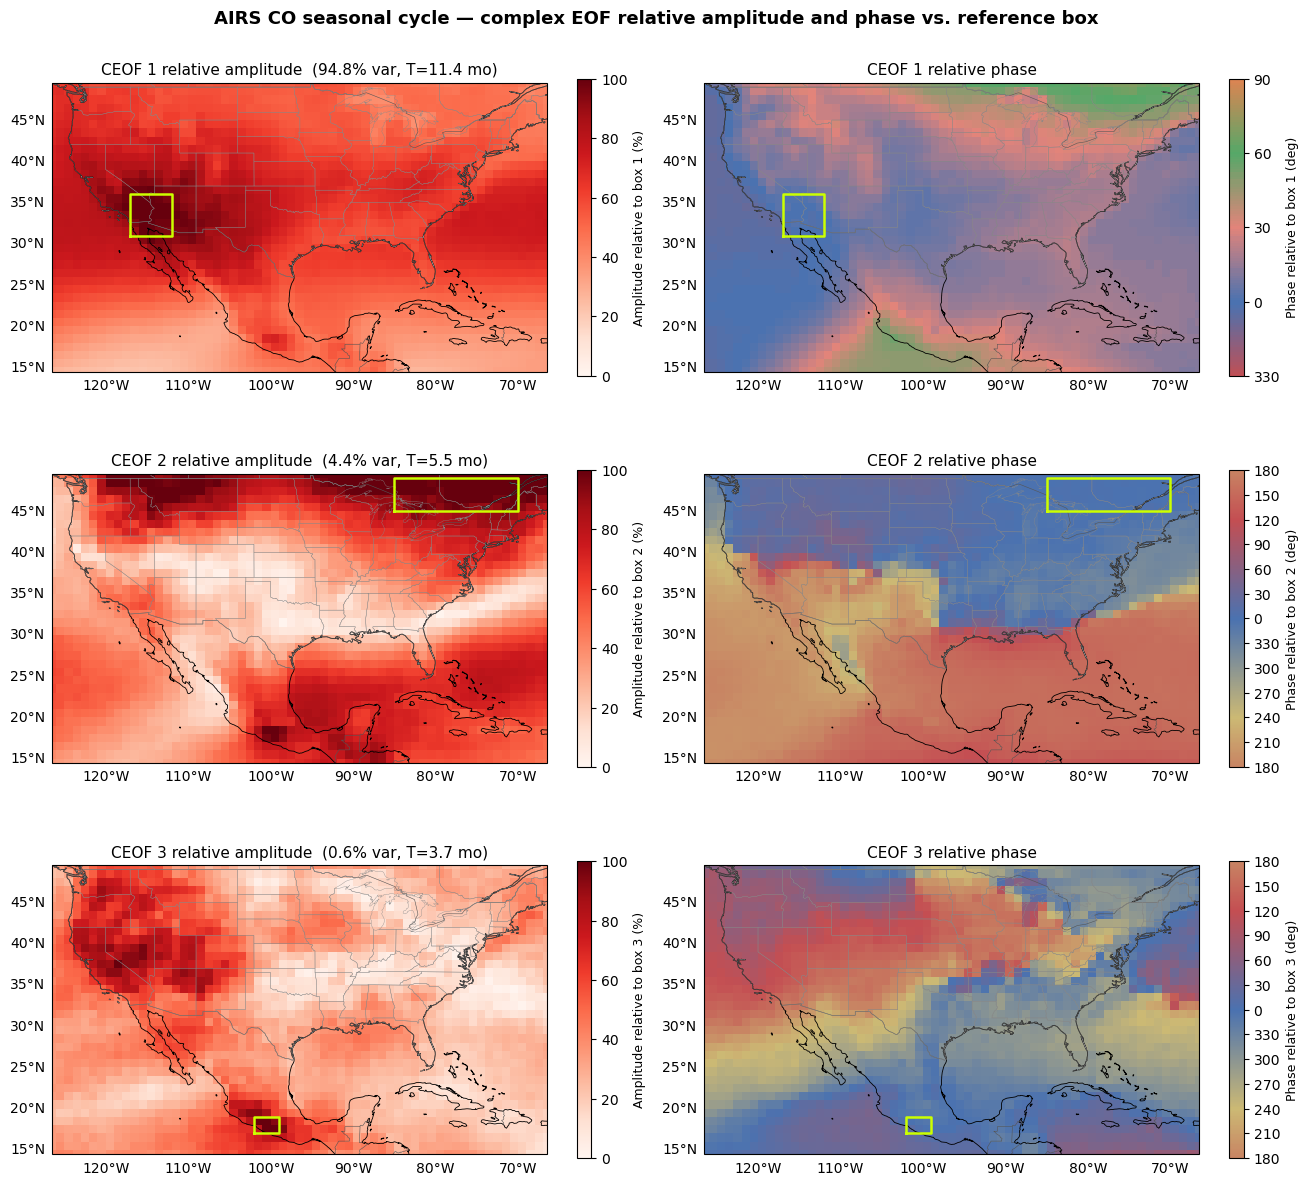

Saved -> ../../Figures/climatology/seasonal-cycle-eofs\ceof_relamp_relphase_modes123.png


In [10]:
relphase_colors = {
    1: ["#4b72b0", "#e2847a", "#55a868", "#dd8452", "#8172b3", "#ccb974",
        "#64b5cd", "#59a14f", "#b07aa1", "#2f4b7c", "#e09f53", "#c44e52"],
    2: ["#4b72b0", "#c44e52", "#ccb974"],      # circular: blue -> red -> sand -> blue
    3: ["#4b72b0", "#c44e52", "#ccb974"],
}

def double_relphase_cmap(colors):
    """Cyclic colormap doubled over -360..360 so the colorbar can be centred on the 0/360 seam."""
    cmap = mcolors.LinearSegmentedColormap.from_list("relphase", colors + [colors[0]], N=360)
    dcmap = mcolors.ListedColormap([cmap((v % 360) / 360) for v in np.linspace(-360, 360, 721)])
    return dcmap, mcolors.Normalize(vmin=-360, vmax=360)

ceof_ref = {}     # complex box reference per mode (used again for the reconstructions)

fig_ap, axes_ap = plt.subplots(n_show, 2, figsize=(13, 4 * n_show),
                               subplot_kw={"projection": ccrs.PlateCarree()}, constrained_layout=True)
for i, k in enumerate(MODES_CMP):
    comp_k = ceofs.sel(mode=k)
    ref = box_mean(comp_k, k)
    ceof_ref[k] = ref
    b = BOXES[k]
    coherence = float(np.abs(ref) / np.abs(comp_k.sel(lat=slice(b["LAT0"], b["LAT1"]),
                                                       lon=slice(b["LON0"], b["LON1"]))).mean())

    amp_gain  = 100 * np.abs(comp_k.values) / np.abs(ref.values)
    rel_phase = np.rad2deg(np.angle(comp_k.values * np.conj(ref.values)))    # -180..180

    map_panel(axes_ap[i, 0], amp_gain, "Reds", f"Amplitude relative to box {k} (%)",
              f"CEOF {k} relative amplitude  ({cexpvar[k-1]:.1f}% var, T={mode_periods[k]:.1f} mo)",
              vmin=0, vmax=100)

    dcmap, dnorm = double_relphase_cmap(relphase_colors[k])
    cb = map_panel(axes_ap[i, 1], rel_phase, dcmap, f"Phase relative to box {k} (deg)",
                   f"CEOF {k} relative phase", norm=dnorm)
    lo = np.floor(np.nanmin(rel_phase) / 30) * 30
    hi = np.ceil(np.nanmax(rel_phase) / 30) * 30
    cb.ax.set_ylim(lo, hi)
    ticks = np.arange(lo, hi + 1e-6, 30)
    cb.set_ticks(ticks)
    cb.set_ticklabels([f"{int(t % 360)}" for t in ticks])

    for ax in axes_ap[i]:
        draw_box(ax, k)
    print(f"Mode {k}: box coherence = {coherence:.4f}")

fig_ap.suptitle("AIRS CO seasonal cycle — complex EOF relative amplitude and phase vs. reference box",
                fontsize=13, fontweight="bold")
out_ap = os.path.join(OUT_DIR, "ceof_relamp_relphase_modes123.png")
fig_ap.savefig(out_ap, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_ap)

### Complex EOF reconstructed signal over each box: Re[ PC_k(t) · conj(box reference) ]

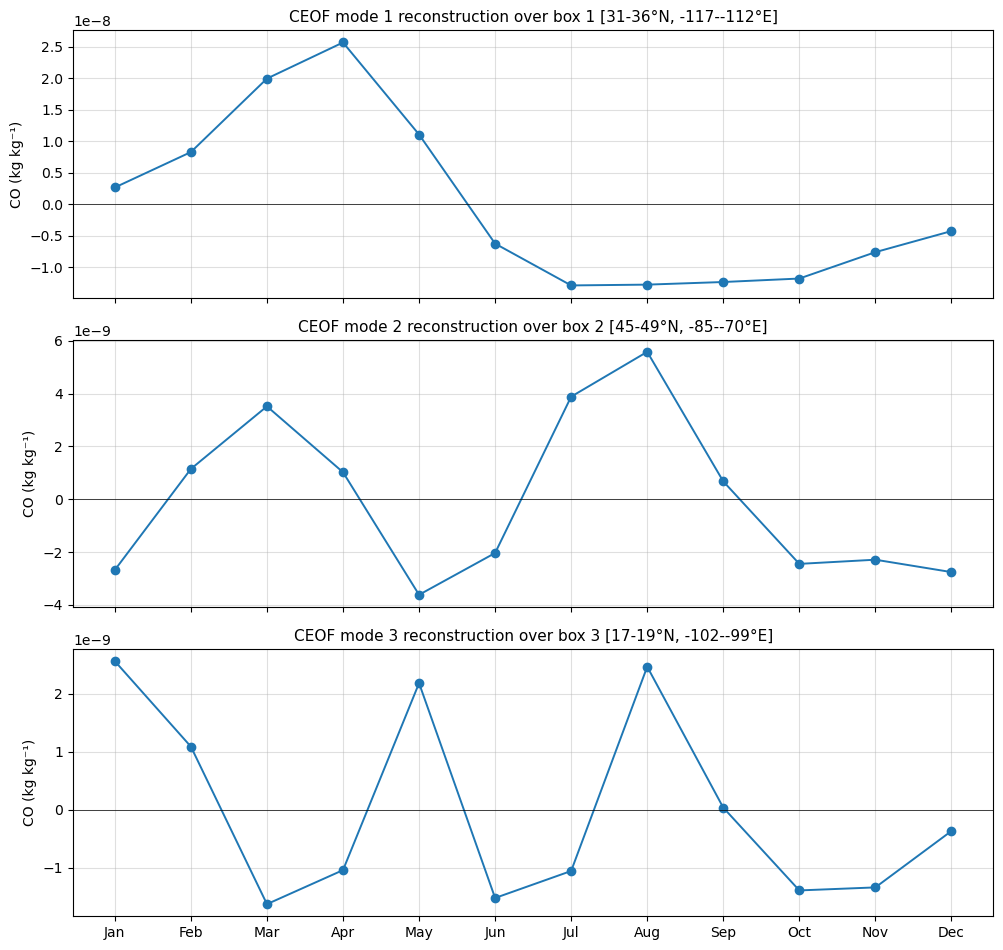

Saved -> ../../Figures/climatology/seasonal-cycle-eofs\ceof_recon_box_modes123.png


In [11]:
fig_cr, axes_cr = plt.subplots(n_show, 1, figsize=(10, 3.2 * n_show), sharex=True)
for ax, k in zip(axes_cr, MODES_CMP):
    recon_k = (cpcs.sel(mode=k) * np.conj(ceof_ref[k])).real
    ax.plot(mpos, recon_k.values, "o-", lw=1.4, color="#1f77b4")
    month_axis(ax)
    ax.set_ylabel("CO (kg kg⁻¹)")
    ax.set_title(f"CEOF mode {k} reconstruction over {box_label(k)}", fontsize=11)
fig_cr.tight_layout()
out_cr = os.path.join(OUT_DIR, "ceof_recon_box_modes123.png")
fig_cr.savefig(out_cr, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_cr)